# UT1. L'anàlisi exploratòria — notebook

Aquest notebook reprodueix, de manera executable, tot el codi Python de la teoria de la UT1 del mòdul de Depuració, neteja i classificació de dades (DNC): creació del conjunt de dades, primer contacte, diccionari de dades i relacions entre variables. Segueix el mateix ordre i les mateixes dades que les diapositives; les explicacions purament conceptuals (definicions, diagrames, fórmules) hi queden fora i es troben només a la teoria.

## El conjunt de dades d'aquesta unitat

Conjunt propi i sintètic de reserves de vehicles, amb defectes deliberats (com en qualsevol dada real): `zona` té variants d'escriptura, `km` inclou un valor sentinella (9999) i `import` està codificat com a text amb coma decimal.

In [1]:
import pandas as pd

# zona té variants d'escriptura; km inclou un valor sentinella (9999)
df = pd.DataFrame({
    "id": ["R001", "R002", "R003", "R004", "R005",
           "R006", "R007", "R008", "R009", "R010"],
    "zona": ["PALMA", "Palma", "CALVIA", "palma ", "LLEVANT",
             "NORD", "Calvia", "Llevant", "Nord", "PALMA"],
    "km": [12.4, 8.1, 25.6, 15.0, 9999,
           33.2, 18.7, 21.3, 6.5, 40.1],
    "import": ["45,20", "30,00", "78,50", "52,90", "110,00",
               "95,40", "60,10", "70,00", "25,00", "132,75"],
    "estat": ["confirmada", "confirmada", "cancel·lada", "confirmada",
              "pendent", "confirmada", "confirmada", "cancel·lada",
              "confirmada", "confirmada"],
    "passatgers": [2, 1, 3, 2, 4, 1, 2, 3, 1, 4],
})

## Comprovem que s'ha creat

Dues comandes bàsiques confirmen que el `df` existeix i té la mida esperada:

In [2]:
print(df.head(3))  # primeres 3 files
print(df.shape)  # (n_files, n_columnes)

     id    zona    km import        estat  passatgers
0  R001   PALMA  12.4  45,20   confirmada           2
1  R002   Palma   8.1  30,00   confirmada           1
2  R003  CALVIA  25.6  78,50  cancel·lada           3
(10, 6)


## Ampliem el dataset: temporal i identificador

Afegim una variable temporal (`creada_el`) i un identificador personal (`email`). `creada_el` permetrà derivar-hi dia de la setmana o mes; `email` és un identificador personal — fora del conjunt d'entrenament per risc de privacitat (RGPD).

In [3]:
# Afegim una variable temporal i un identificador personal
df["creada_el"] = pd.to_datetime([
    "2026-01-05", "2026-01-06", "2026-01-07", "2026-01-09",
    "2026-01-10", "2026-01-12", "2026-01-13", "2026-01-15",
    "2026-01-16", "2026-01-18",
])
df["email"] = [f"usuari{n:02d}@correu.cat" for n in range(1, 11)]

## Radiografia inicial amb pandas

La seqüència canònica de primer contacte: dimensions, tipus, mostra, cardinalitats i estadístics.

In [4]:
print("Dimensions:", df.shape)  # (files, columnes)
print(df.dtypes)  # tipus inferit de cada columna
print(df.sample(3, random_state=7))  # mostra aleatòria

print(df.nunique().sort_values())  # cardinalitats
print(df.describe(include="number").round(2))  # estadístics
print(df["zona"].value_counts())  # freqüències de zona

Dimensions: (10, 8)
id                       str
zona                     str
km                   float64
import                   str
estat                    str
passatgers             int64
creada_el     datetime64[us]
email                    str
dtype: object
     id   zona    km import       estat  passatgers  creada_el  \
8  R009   Nord   6.5  25,00  confirmada           1 2026-01-16   
5  R006   NORD  33.2  95,40  confirmada           1 2026-01-12   
0  R001  PALMA  12.4  45,20  confirmada           2 2026-01-05   

                 email  
8  usuari09@correu.cat  
5  usuari06@correu.cat  
0  usuari01@correu.cat  
estat          3
passatgers     4
zona           9
id            10
import        10
km            10
creada_el     10
email         10
dtype: int64
            km  passatgers
count    10.00       10.00
mean   1017.99        2.30
std    3155.62        1.16
min       6.50        1.00
25%      13.05        1.25
50%      20.00        2.00
75%      31.30        3.00
max 

## Generar un esborrany automàtic del diccionari de dades

Recorre cada columna i en resumeix el tipus, la cardinalitat i el percentatge d'absents. Aquest esborrany cobreix, aproximadament, el 60 % del diccionari; el domini esperat, les unitats i el significat de negoci els ha d'afegir una persona que conegui les dades.

In [5]:
# Recorre cada columna i en resumeix tipus, cardinalitat i buits
files = []
for col in df.columns:
    s = df[col]
    files.append({
        "variable": col,
        "tipus": str(s.dtype),
        "n_unics": int(s.nunique()),
        "pct_absents": round(100 * s.isna().mean(), 1),
        "exemple": repr(s.iloc[0]),
    })

diccionari = pd.DataFrame(files)
print(diccionari.to_string(index=False))

  variable          tipus  n_unics  pct_absents                          exemple
        id            str       10          0.0                           'R001'
      zona            str        9          0.0                          'PALMA'
        km        float64       10          0.0                 np.float64(12.4)
    import            str       10          0.0                          '45,20'
     estat            str        3          0.0                     'confirmada'
passatgers          int64        4          0.0                      np.int64(2)
 creada_el datetime64[us]       10          0.0 Timestamp('2026-01-05 00:00:00')
     email            str       10          0.0            'usuari01@correu.cat'


## Calculant les tres mirades de relacions amb pandas

Numèrica × numèrica (correlació), categòrica × numèrica (estadístics per grup) i categòrica × categòrica (taula de contingència).

In [6]:
df["import_num"] = df["import"].str.replace(",", ".").astype(float)

print(df[["km", "import_num"]].corr())                 # num x num
print(df.groupby("estat")["import_num"]
        .agg(["count", "mean"]).round(2))               # cat x num
print(pd.crosstab(df["zona"], df["estat"]))              # cat x cat

                  km  import_num
km          1.000000    0.407331
import_num  0.407331    1.000000
             count    mean
estat                     
cancel·lada      2   74.25
confirmada       7   63.05
pendent          1  110.00
estat    cancel·lada  confirmada  pendent
zona                                     
CALVIA             1           0        0
Calvia             0           1        0
LLEVANT            0           0        1
Llevant            1           0        0
NORD               0           1        0
Nord               0           1        0
PALMA              0           2        0
Palma              0           1        0
palma              0           1        0


## Dispersió km–import (reproduïda amb matplotlib)

A la teoria aquest gràfic es dibuixa amb TikZ a partir de coordenades calculades a mà; aquí es genera de debò a partir del `df`. `R005` (km=9999) queda fora de l'escala representada — és el valor sentinella que trencaria la relació creixent si s'hi inclogués.

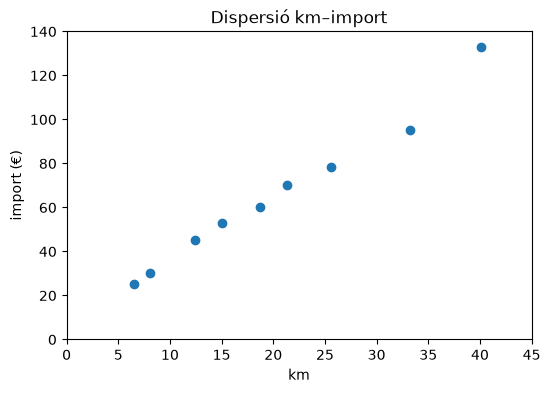

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(df["km"], df["import_num"])
ax.set_xlim(0, 45)
ax.set_ylim(0, 140)
ax.set_xlabel("km")
ax.set_ylabel("import (\u20ac)")
ax.set_title("Dispersió km–import")
plt.show()